# E-commerce Sales and Customer Retention Analysis

By Farah Namouri

## Business goal
Understand sales performance, repeat purchases, and product returns
to identify opportunities to improve revenue and customer retention.

## Dataset
TheLook eCommerce — a public synthetic dataset hosted in Google BigQuery.

## Tools
SQL, Google BigQuery, Python, pandas, and matplotlib.

In [2]:
from google.colab import auth
from google.cloud import bigquery

auth.authenticate_user()

client = bigquery.Client(project="elite-coral-515518-p9")

print("BigQuery client ready!")

BigQuery client ready!


In [3]:
# Reference the public e-commerce dataset
dataset_ref = client.dataset(
    "thelook_ecommerce",
    project="bigquery-public-data"
)

# Print the available table names
for table in client.list_tables(dataset_ref):
    print(table.table_id)

distribution_centers
events
inventory_items
order_items
orders
products
users


In [4]:
# inspecting these 3 tables
table_names = ["orders", "order_items", "products"]

# going through the tables one at a time
for table_name in table_names:

    # Build the address of the current table
    table_ref = dataset_ref.table(table_name)

    # Fetch information about the table, including its columns
    table = client.get_table(table_ref)

    # Print a heading so we know which table we are looking at
    print(f"\n--- {table_name} ---")

    # Print each column's name and data type
    for field in table.schema:
        print(field.name, field.field_type)


--- orders ---
order_id INTEGER
user_id INTEGER
status STRING
gender STRING
created_at TIMESTAMP
returned_at TIMESTAMP
shipped_at TIMESTAMP
delivered_at TIMESTAMP
num_of_item INTEGER

--- order_items ---
id INTEGER
order_id INTEGER
user_id INTEGER
product_id INTEGER
inventory_item_id INTEGER
status STRING
created_at TIMESTAMP
shipped_at TIMESTAMP
delivered_at TIMESTAMP
returned_at TIMESTAMP
sale_price FLOAT

--- products ---
id INTEGER
cost FLOAT
category STRING
name STRING
brand STRING
retail_price FLOAT
department STRING
sku STRING
distribution_center_id INTEGER


In [5]:
# Summarize orders by status and show their earliest and latest dates
overview_query = """
    SELECT
        status,
        COUNT(*) AS number_of_orders,
        MIN(created_at) AS earliest_order,
        MAX(created_at) AS latest_order
    FROM `bigquery-public-data.thelook_ecommerce.orders`
    GROUP BY status
    ORDER BY number_of_orders DESC
"""

# Limit this query to processing at most 1 GB of data
safe_config = bigquery.QueryJobConfig(maximum_bytes_billed=10**9)

# Run the SQL query and convert its results into a pandas DataFrame
orders_overview = client.query(
    overview_query,
    job_config=safe_config
).to_dataframe()

# Display the results
display(orders_overview)

,status,number_of_orders,earliest_order,latest_order
0,Shipped,37584,2019-01-18 18:14:41+00:00,2026-11-22 00:25:12.802047+00:00
1,Complete,31126,2019-01-11 05:37:00+00:00,2026-11-22 00:23:36.639172+00:00
2,Processing,24819,2019-02-11 03:16:13+00:00,2026-11-22 00:25:42.077996+00:00
3,Cancelled,18649,2019-01-23 10:40:13+00:00,2026-11-22 00:05:50+00:00
4,Returned,12551,2019-02-19 15:17:11+00:00,2026-11-22 00:25:10.829826+00:00


In [6]:
# check if completed items have a return date or belong to cancelled or returned orders
status_check_query = """
    SELECT
        COUNT(*) AS complete_items,
        COUNTIF(i.returned_at IS NOT NULL) AS items_with_return_date,
        COUNTIF(o.status = 'Cancelled') AS items_in_cancelled_orders,
        COUNTIF(o.status = 'Returned') AS items_in_returned_orders,
        COUNTIF(o.order_id IS NULL) AS items_without_matching_order
    FROM `bigquery-public-data.thelook_ecommerce.order_items` AS i
    LEFT JOIN `bigquery-public-data.thelook_ecommerce.orders` AS o
        ON i.order_id = o.order_id
    WHERE i.status = 'Complete'
      AND i.created_at >= '2025-01-01'
      AND i.created_at < '2026-01-01'
"""

# Limit the query to processing at most 1 GB of data
safe_config = bigquery.QueryJobConfig(maximum_bytes_billed=10**9)

# Run the query and convert its results into a pandas DataFrame
status_check_results = client.query(
    status_check_query,
    job_config=safe_config
).to_dataframe()

# Display the counts so we can check for inconsistencies
display(status_check_results)

,complete_items,items_with_return_date,items_in_cancelled_orders,items_in_returned_orders,items_without_matching_order
0,9880,0,0,0,0


In [9]:
# Calculate revenue, order count, customer count, and average order value;
# creating a one-row summary of the store’s completed sales
# from orders placed in 2025. This gives us a starting point before
# exploring products and repeat purchases.
sales_summary_query = """
    SELECT
        ROUND(SUM(i.sale_price), 2) AS completed_sales_revenue,
        COUNT(DISTINCT i.order_id) AS number_of_orders,
        COUNT(DISTINCT o.user_id) AS number_of_customers,
        COUNT(*) AS number_of_items,
        ROUND(
            SUM(i.sale_price) / COUNT(DISTINCT i.order_id),
            2
        ) AS average_order_value
    FROM `bigquery-public-data.thelook_ecommerce.order_items` AS i
    INNER JOIN `bigquery-public-data.thelook_ecommerce.orders` AS o
        ON i.order_id = o.order_id
    WHERE o.created_at >= '2025-01-01'
      AND o.created_at < '2026-01-01'
      AND i.status = 'Complete'
      AND i.returned_at IS NULL
      AND o.status NOT IN ('Cancelled', 'Returned')
"""

# Run the query using our existing 1 GB processing limit
sales_summary = client.query(
    sales_summary_query,
    job_config=safe_config
).to_dataframe()

# Display the sales metrics
display(sales_summary)

,completed_sales_revenue,number_of_orders,number_of_customers,number_of_items,average_order_value
0,588586.77,6869,6603,9886,85.69


from the code above: There are more orders than customers, so some customers purchased more than once

In [10]:
# find which product categories generated the most completed sales revenue
# Calculate completed sales revenue and item count for each product category
category_sales_query = """
    SELECT
        p.category,
        ROUND(SUM(i.sale_price), 2) AS completed_sales_revenue,
        COUNT(*) AS number_of_items
    FROM `bigquery-public-data.thelook_ecommerce.order_items` AS i

    -- Connect each item to its order so we can filter by order date
    INNER JOIN `bigquery-public-data.thelook_ecommerce.orders` AS o
        ON i.order_id = o.order_id

    -- Connect each item to its product to get the category
    INNER JOIN `bigquery-public-data.thelook_ecommerce.products` AS p
        ON i.product_id = p.id

    -- Apply the same date and status rules as our sales summary
    WHERE o.created_at >= '2025-01-01'
      AND o.created_at < '2026-01-01'
      AND i.status = 'Complete'
      AND i.returned_at IS NULL
      AND o.status NOT IN ('Cancelled', 'Returned')

    -- Produce one row per category, with the highest revenue first(DESC)
    GROUP BY p.category
    ORDER BY completed_sales_revenue DESC
"""

# Run the query using our existing 1 GB processing limit
category_sales = client.query(
    category_sales_query,
    job_config=safe_config
).to_dataframe()

# Display revenue and item counts by category
display(category_sales)

,category,completed_sales_revenue,number_of_items
0,Outerwear & Coats,73213.99,502
1,Jeans,67202.89,669
2,Sweaters,44914.73,603
3,Swim,37537.44,657
4,Fashion Hoodies & Sweatshirts,37072.44,672
5,Suits & Sport Coats,34163.39,269
6,Shorts,28582.76,659
7,Sleep & Lounge,28365.53,572
8,Tops & Tees,27088.54,635
9,Active,26032.88,487


from the code above: Outerwear & Coats generated the most revenue, while Intimates sold the most items. Revenue depends on both how many items sell and their prices.

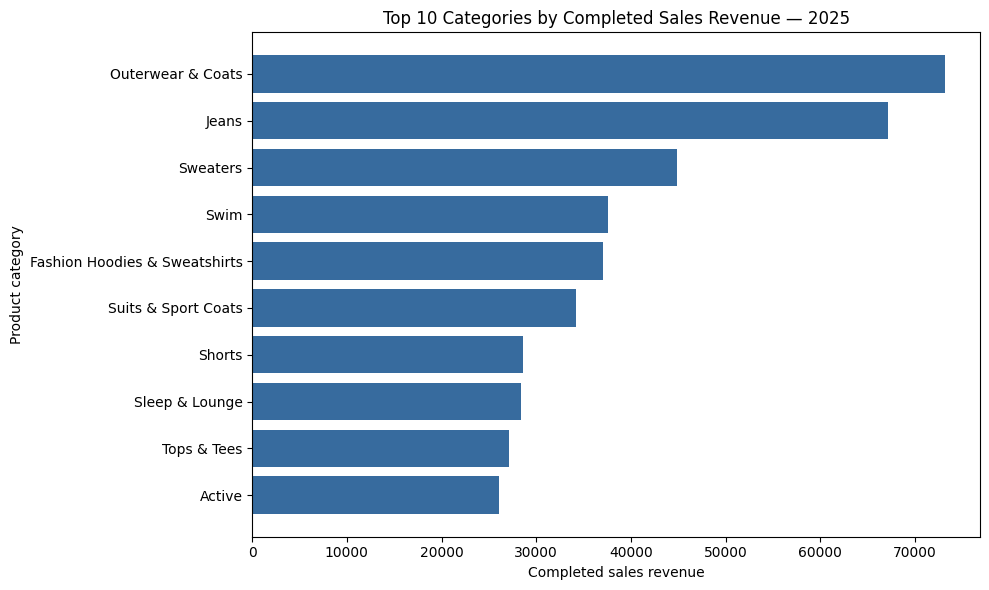

In [11]:
# Import Python's plotting library
import matplotlib.pyplot as plt

# Select the first 10 categories from our revenue-sorted results
top_categories = category_sales.head(10)

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

# Plot category names against completed sales revenue
ax.barh(
    top_categories["category"],
    top_categories["completed_sales_revenue"],
    color="#376B9E"
)

# Place the highest-revenue category at the top
ax.invert_yaxis()

# Add a title and axis labels
ax.set_title("Top 10 Categories by Completed Sales Revenue — 2025")
ax.set_xlabel("Completed sales revenue")
ax.set_ylabel("Product category")

# Adjust spacing so the labels fit
plt.tight_layout()

# Save the chart for our GitHub project
plt.savefig("top_10_categories_revenue.png", dpi=150, bbox_inches="tight")

# Display the chart
plt.show()

In [12]:
# Count eligible orders per customer, then calculate the repeat purchase rate
repeat_customers_query = """
    WITH customer_orders AS (
        -- Count each order once, even when it contains multiple items
        SELECT
            o.user_id,
            COUNT(DISTINCT o.order_id) AS number_of_orders
        FROM `bigquery-public-data.thelook_ecommerce.order_items` AS i
        INNER JOIN `bigquery-public-data.thelook_ecommerce.orders` AS o
            ON i.order_id = o.order_id

        -- Use the same date and status rules as our sales summary
        WHERE o.created_at >= '2025-01-01'
          AND o.created_at < '2026-01-01'
          AND i.status = 'Complete'
          AND i.returned_at IS NULL
          AND o.status NOT IN ('Cancelled', 'Returned')

        -- Produce one row per customer
        GROUP BY o.user_id
    )

    SELECT
        COUNT(*) AS total_customers,
        COUNTIF(number_of_orders >= 2) AS repeat_customers,
        ROUND(
            100.0 * SAFE_DIVIDE(
                COUNTIF(number_of_orders >= 2),
                COUNT(*)
            ),
            2
        ) AS repeat_purchase_rate_pct
    FROM customer_orders
"""

# Run the query using our existing processing limit
repeat_customers_results = client.query(
    repeat_customers_query,
    job_config=safe_config
).to_dataframe()

# Display customer counts and the repeat purchase percentage
display(repeat_customers_results)

,total_customers,repeat_customers,repeat_purchase_rate_pct
0,6603,258,3.91


the code above measures repeat purchases within 2025. 258 of 6,603 customers placed at least two eligible orders in 2025 — a repeat purchase rate of 3.91%. The other 6,345 placed one eligible order during that year.

In [13]:
# Calculate the percentage of completed-or-returned items that were returned
returns_query = """
    SELECT
        p.category,
        COUNT(*) AS completed_or_returned_items,
        COUNTIF(i.status = 'Returned') AS returned_items,
        ROUND(
            100.0 * SAFE_DIVIDE(
                COUNTIF(i.status = 'Returned'),
                COUNT(*)
            ),
            2
        ) AS return_rate_pct
    FROM `bigquery-public-data.thelook_ecommerce.order_items` AS i

    -- Join orders to filter by the year the order was placed
    INNER JOIN `bigquery-public-data.thelook_ecommerce.orders` AS o
        ON i.order_id = o.order_id

    -- Join products to identify each item's category
    INNER JOIN `bigquery-public-data.thelook_ecommerce.products` AS p
        ON i.product_id = p.id

    -- Include completed and returned items from orders placed in 2025
    WHERE o.created_at >= '2025-01-01'
      AND o.created_at < '2026-01-01'
      AND i.status IN ('Complete', 'Returned')

    -- Calculate one result per category
    GROUP BY p.category

    -- Show the highest return percentages first
    ORDER BY return_rate_pct DESC
"""

# Run the query using our existing processing limit
category_returns = client.query(
    returns_query,
    job_config=safe_config
).to_dataframe()

# Display return rates alongside the item counts behind them
display(category_returns)

,category,completed_or_returned_items,returned_items,return_rate_pct
0,Leggings,245,86,35.10
1,Sleep & Lounge,872,300,34.40
2,Accessories,741,228,30.77
3,Socks,455,136,29.89
4,Maternity,389,116,29.82
5,Active,693,206,29.73
6,Suits & Sport Coats,381,112,29.40
7,Tops & Tees,892,257,28.81
8,Blazers & Jackets,221,63,28.51
9,Socks & Hosiery,278,79,28.42


from the output of the code above:
Leggings has the highest return rate at 35.10%, while Sleep & Lounge has the most returned items — 300 — and a rate of 34.40%. Sleep & Lounge is worth investigating because both its rate and return volume are high.

We can suggest reviewing sizing information, product descriptions, and return reasons. Our data doesn’t establish what caused the returns.

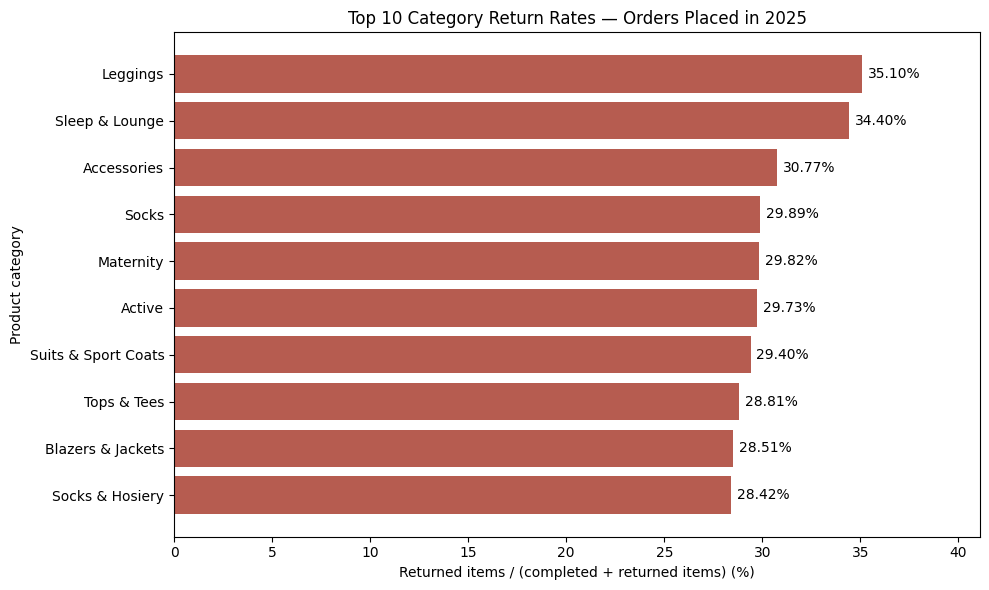

In [14]:
# Select the 10 categories with the highest return rates
top_returns = category_returns.head(10)

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the return percentage for each category
ax.barh(
    top_returns["category"],
    top_returns["return_rate_pct"],
    color="#B65C50"
)

# Put the highest return rate at the top
ax.invert_yaxis()

# Explain the metric in the title and axis label
ax.set_title("Top 10 Category Return Rates — Orders Placed in 2025")
ax.set_xlabel("Returned items / (completed + returned items) (%)")
ax.set_ylabel("Product category")

# Add percentage labels beside the bars
for position, rate in enumerate(top_returns["return_rate_pct"]):
    ax.text(rate + 0.3, position, f"{rate:.2f}%", va="center")

# Leave space for the percentage labels
ax.set_xlim(0, top_returns["return_rate_pct"].max() + 6)

# Adjust spacing and save the chart for GitHub
plt.tight_layout()
plt.savefig("top_10_category_returns.png", dpi=150, bbox_inches="tight")

# Display the chart
plt.show()

In [15]:
# Get the overall revenue and item count from our sales summary
summary_revenue = float(sales_summary.loc[0, "completed_sales_revenue"])
summary_items = int(sales_summary.loc[0, "number_of_items"])

# Add up revenue and item counts across all product categories
category_revenue = float(category_sales["completed_sales_revenue"].sum())
category_items = int(category_sales["number_of_items"].sum())

# Compare revenue totals, allowing a small difference from rounding
print("Revenue totals match:",
      abs(summary_revenue - category_revenue) < 0.05)

# Compare item counts, which should match exactly
print("Item counts match:", summary_items == category_items)

# Compare customer counts across our two analyses
print("Customer counts match:",
      int(sales_summary.loc[0, "number_of_customers"])
      == int(repeat_customers_results.loc[0, "total_customers"]))

Revenue totals match: True
Item counts match: True
Customer counts match: True


## What I found

### Outerwear & Coats and Jeans brought in the most revenue
Outerwear & Coats generated 73,213.99 in completed sales, followed
by Jeans at 67,202.89. These categories would be a good place to
review stock availability and profit margins before deciding
whether to invest more in promotion.

### Most customers purchased only once during 2025
Out of 6,603 customers with eligible purchases, 258 placed more
than one eligible order during the year. That gives a repeat
purchase rate of 3.91%.

A possible next step would be to test a follow-up campaign after
the first purchase and track whether it encourages a second order.

### Some categories had higher return rates
Leggings had the highest return rate at 35.10%. Sleep & Lounge
stood out too, with a rate of 34.40% and 300 returned items,
the largest return count of any category.

I would investigate the reasons behind these returns first.
Sizing guidance and product descriptions are possible areas
to review, but this dataset cannot tell us what caused the returns.

## How to interpret these results

I used synthetic data from TheLook eCommerce and focused on orders
placed in 2025, using their recorded status when the analysis ran.

For sales revenue, I included completed items with no return date
and excluded cancelled or returned orders. The repeat purchase rate
counts customers who made at least two eligible purchases within
2025. The return rate compares returned items with the total number
of completed and returned items.

These findings suggest areas to investigate. Any proposed campaign
or product change would need testing to measure its impact.

## Checks I performed

I checked that revenue and item counts across the product categories
matched the overall sales summary. I also confirmed that the sales
summary and repeat purchase analysis used the same customer count.
All three checks passed.
